# Step 7 — 2D Diffusion

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/jejjohnson/sesmax/blob/main/docs/notebooks/step07_diffusion_2d.ipynb)

*The "12 steps to Navier-Stokes" with sesmax (after Lorena Barba's CFD Python), moved from somax's tutorial series.*

The 2D diffusion (heat) equation spreads a field from high to low values and has an exact Gaussian solution to validate the solver against.

**What you will learn:**

1. How diffusion smooths a 2D field
2. Validation against the analytical Gaussian solution
3. Energy dissipation in 2D
4. Differentiating through the diffusion coefficient $\nu$

## Setup

On Colab, install `sesmax-core`; locally, with the repository's environment, this does nothing.

In [1]:
import subprocess
import sys


try:
    import google.colab  # noqa: F401

    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    subprocess.run(
        [
            sys.executable,
            "-m",
            "pip",
            "install",
            "-q",
            "sesmax-core @ git+https://github.com/jejjohnson/sesmax@main"
            "#subdirectory=packages/sesmax-core",
        ],
        check=True,
    )

## The PDE

$$
\frac{\partial u}{\partial t} = \nu \left(\frac{\partial^2 u}{\partial x^2} + \frac{\partial^2 u}{\partial y^2}\right)
$$

Diffusion spreads concentration from high to low regions. A 2D Gaussian initial condition remains Gaussian for all time, with a width that grows as $\sigma(t) = \sqrt{\sigma_0^2 + 2 \nu t}$. The peak decays as $\sigma_0^2 / \sigma(t)^2$ so that total mass is conserved. This analytical solution provides an exact benchmark for the numerical solver.

### Symbols

The page uses the classic CFD letters. Everything is nondimensional, and $x$ and $y$ are the spatial coordinates (there is no inference state on this page).

| Symbol | Meaning | Shape |
| --- | --- | --- |
| $x \in [0, L_x)$, $y \in [0, L_y)$ | spatial coordinates | $\mathbb{R}$ |
| $t \in [t_0, t_1]$ | time | $\mathbb{R}$ |
| $u(x, y, t)$ | the diffusing field | $\mathbb{R}$ |
| $u_0(x, y)$ | initial condition, a Gaussian bump with centre $(\mu_x, \mu_y)$ and width $\sigma_0$ | $\mathbb{R}$ |
| $\sigma(t)$ | width of the exact Gaussian solution at time $t$ | $\mathbb{R}_{>0}$ |
| $\nu$ | diffusion coefficient, the model's differentiable parameter | $\mathbb{R}_{>0}$ |
| $L_x$, $L_y$ | domain lengths | $\mathbb{R}_{>0}$ |
| $N_x$, $N_y$ | number of interior grid cells along $x$ and $y$ | count |
| $\Delta x = L_x / N_x$, $\Delta y = L_y / N_y$, $\Delta t$ | grid spacings and time step | $\mathbb{R}_{>0}$ |
| $u_{j,i}$ | the field in the cell at row $j$ and column $i$; the array has $N_y + 2$ rows and $N_x + 2$ columns with the ghosts | $\mathbb{R}$ |
| $E(t)$ | energy | $\mathbb{R}_{\ge 0}$ |
| $\mathcal{L}$ | loss, minimised | $\mathbb{R}$ |

## Grid layout and boundary conditions

In 2D, sesmax uses the **Arakawa C-grid** from finitevolX, where different variables live at different positions within each cell:

| Point | Location in cell $(i, j)$ | Holds |
| --- | --- | --- |
| T-points | cell centre | scalars, such as the diffusing field |
| U-points | east and west faces, $i \pm \frac{1}{2}$ | fluxes in $x$ |
| V-points | north and south faces, $j \pm \frac{1}{2}$ | fluxes in $y$ |
| X-points | corners | vorticity (in some formulations) |

The full array has $N_y + 2$ rows and $N_x + 2$ columns, with a one-cell **ghost ring** on all sides around the $N_y \times N_x$ interior cells:

| Array axis | `0` | `1` … `N` | `N + 1` (or `-1`) |
| --- | --- | --- | --- |
| Rows (`N = N_y`) | south ghost row | interior rows | north ghost row |
| Columns (`N = N_x`) | west ghost column | interior columns | east ghost column |

The interior cells are `[1:-1, 1:-1]`. The ghost cells are filled by the boundary conditions before each evaluation of the right-hand side.

**Periodic BCs** (`enforce_periodic`) copy the last interior row or column into the opposite ghost row or column:

- the south ghost row takes the north interior row, $u_{0,i} = u_{N_y,i}$
- the north ghost row takes the south interior row, $u_{N_y + 1,i} = u_{1,i}$
- the west ghost column takes the east interior column, $u_{j,0} = u_{j,N_x}$
- the east ghost column takes the west interior column, $u_{j,N_x + 1} = u_{j,1}$

In [2]:
import diffrax as dfx
import einx
import equinox as eqx
import jax.numpy as jnp
import matplotlib.pyplot as plt

import sesmax_core.testing as sxt

In [3]:
import importlib.util


try:
    from IPython import get_ipython

    ipython = get_ipython()
except ImportError:
    ipython = None

if ipython is not None and importlib.util.find_spec("watermark") is not None:
    ipython.run_line_magic("load_ext", "watermark")
    ipython.run_line_magic("watermark", "-v -m -p jax,equinox,diffrax,sesmax_core")
else:
    print("watermark extension not installed; skipping reproducibility readout.")

Python implementation: CPython
Python version       : 3.13.12
IPython version      : 9.10.0

jax        : 0.12.0.1
equinox    : 0.13.8
diffrax    : 0.7.2
sesmax_core: 0.0.0

Compiler    : Clang 21.1.4 
OS          : Linux
Release     : 6.8.0-1044-azure
Machine     : x86_64
Processor   : x86_64
CPU cores   : 16
Architecture: 64bit



## 1. Create the model

`Diffusion2D.create()` builds a model on a 2D Arakawa C-grid with `nx` by `ny` interior cells spanning a domain of size `Lx` by `Ly`. The diffusion coefficient `nu` is a differentiable parameter visible to `jax.grad`.

In [4]:
# Shapes: N_x = 64, N_y = 64 interior cells

num_cells_x = 64
num_cells_y = 64
domain_length_x = 4.0
domain_length_y = 4.0
viscosity = 0.05

# today (sesmax_core)
model = sxt.Diffusion2D.create(
    nx=num_cells_x,
    ny=num_cells_y,
    Lx=domain_length_x,
    Ly=domain_length_y,
    nu=viscosity,
)

print(model)
print(f"Grid: Nx={model.grid.Nx}, Ny={model.grid.Ny}")
print(f"Spacing: dx={model.grid.dx:.4f}, dy={model.grid.dy:.4f}")

Diffusion2D(
  params=Diffusion2DParams(nu=weak_f32[]),
  grid=CartesianGrid2D(Nx=66, Ny=66, Lx=4.0, Ly=4.0, dx=0.0625, dy=0.0625),
  diff=Difference2D(
    grid=CartesianGrid2D(Nx=66, Ny=66, Lx=4.0, Ly=4.0, dx=0.0625, dy=0.0625)
  ),
  mask=None
)
Grid: Nx=66, Ny=66
Spacing: dx=0.0625, dy=0.0625


## 2. Initial condition

A 2D Gaussian bump with centre $(\mu_x, \mu_y) = (2, 2)$ and width $\sigma_0 = 0.3$:

$$
u_0(x, y) = \exp\left(-\frac{(x - \mu_x)^2 + (y - \mu_y)^2}{2 \sigma_0^2}\right)
$$

In [5]:
# Shapes: N_x + 2 = 66 columns and N_y + 2 = 66 rows with the ghosts

centre_x = 2.0
centre_y = 2.0
bump_width = 0.3
inner = slice(1, -1)
interior = (inner, inner)

# xᵢ = i Δx
x_position = jnp.arange(model.grid.Nx) * model.grid.dx  # → (N_x + 2,)
# yⱼ = j Δy
y_position = jnp.arange(model.grid.Ny) * model.grid.dy  # → (N_y + 2,)
# (xᵢ, yⱼ) on every cell
x_grid, y_grid = jnp.meshgrid(x_position, y_position)  # → (N_y + 2, N_x + 2) each
# zₓ = (x − μₓ) / σ₀
standardised_x = (x_grid - centre_x) / bump_width  # → (N_y + 2, N_x + 2)
# z_y = (y − μ_y) / σ₀
standardised_y = (y_grid - centre_y) / bump_width  # → (N_y + 2, N_x + 2)
# u₀(x, y) = exp(−(zₓ² + z_y²) / 2)
radius_squared = standardised_x**2 + standardised_y**2  # → (N_y + 2, N_x + 2)
initial_u = jnp.exp(-0.5 * radius_squared)  # → (N_y + 2, N_x + 2)

# today (sesmax_core)
initial_state = sxt.Diffusion2DState(u=initial_u)

print(f"State shape: u={initial_state.u.shape}")
print(f"Peak value: {float(jnp.max(initial_u)):.4f}")

State shape: u=(66, 66)
Peak value: 1.0000


## 3. Run the simulation

We integrate from $t_0 = 0$ to $t_1 = 1$ and save a snapshot every time step.

In [6]:
# Shapes: N_T = 500 saved snapshots; N_y + 2 = 66 rows and N_x + 2 = 66 columns

time_step = 0.002
start_time = 0.0
end_time = 1.0

# tₖ = t₀ + k Δt
save_times = jnp.arange(start_time, end_time, time_step)  # → (N_T,)

# today (sesmax_core, diffrax)
# u(x, y, tₖ) for each saved time
solution = model.integrate(  # u → (N_T, N_y + 2, N_x + 2)
    initial_state,
    t0=start_time,
    t1=end_time,
    dt=time_step,
    saveat=dfx.SaveAt(ts=save_times),
)

print(f"Solution shape: {solution.ys.u.shape}")

Solution shape: (500, 66, 66)


## 4. Visualize spreading

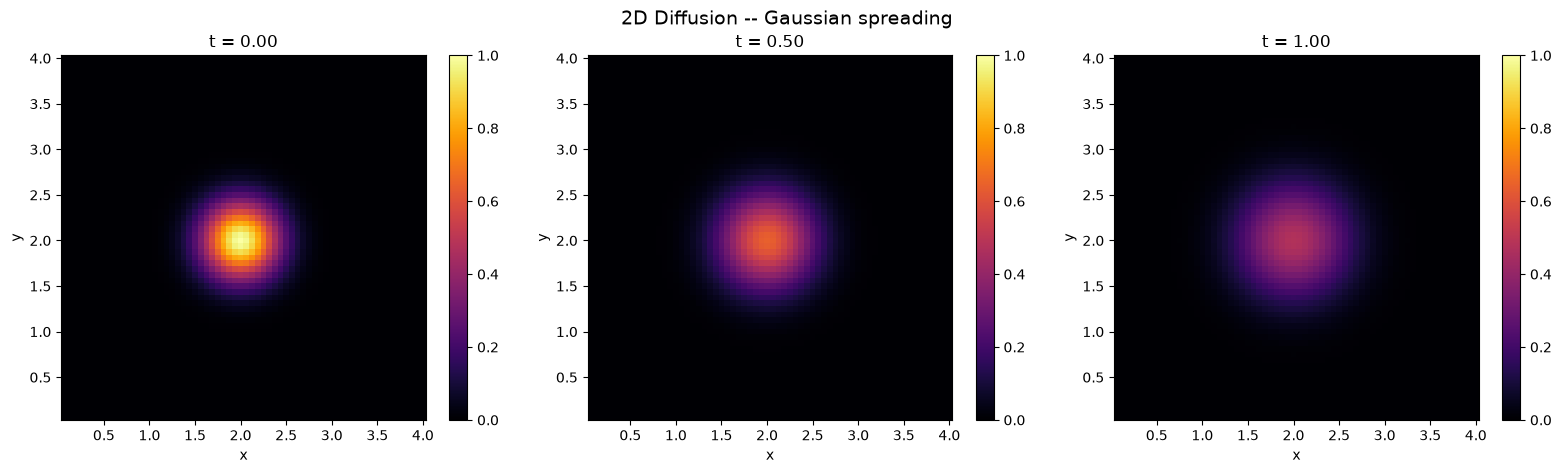

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

snapshots = [0, len(save_times) // 2, -1]
for ax, snapshot in zip(axes, snapshots, strict=True):
    snapshot_time = float(save_times[snapshot])
    field = solution.ys.u[snapshot]
    pcm = ax.pcolormesh(
        x_grid[interior],
        y_grid[interior],
        field[interior],
        shading="auto",
        cmap="inferno",
        vmin=0.0,
        vmax=1.0,
    )
    plt.colorbar(pcm, ax=ax)
    ax.set_xlabel("x")
    ax.set_ylabel("y")
    ax.set_title(f"t = {snapshot_time:.2f}")
    ax.set_aspect("equal")

plt.suptitle("2D Diffusion -- Gaussian spreading", fontsize=14)
plt.tight_layout()
plt.show()

## 5. Analytical comparison

The exact solution for a Gaussian initial condition under 2D diffusion is:

$$
u_\text{exact}(x, y, t) = \frac{\sigma_0^2}{\sigma(t)^2} \exp\left(-\frac{(x - \mu_x)^2 + (y - \mu_y)^2}{2 \sigma(t)^2}\right)
$$

$$
\sigma(t) = \sqrt{\sigma_0^2 + 2 \nu t}
$$

In [8]:
# Shapes: N_y + 2 = 66 rows and N_x + 2 = 66 columns with the ghosts

final_time = float(save_times[-1])

# σ(t₁) = (σ₀² + 2 ν t₁)^½
final_width = jnp.sqrt(bump_width**2 + 2.0 * viscosity * final_time)  # → ()
# zₓ = (x − μₓ) / σ(t₁)
exact_standardised_x = (x_grid - centre_x) / final_width  # → (N_y + 2, N_x + 2)
# z_y = (y − μ_y) / σ(t₁)
exact_standardised_y = (y_grid - centre_y) / final_width  # → (N_y + 2, N_x + 2)
# r² = zₓ² + z_y²
exact_radius_squared = exact_standardised_x**2 + exact_standardised_y**2
# σ₀² / σ(t₁)²
amplitude = bump_width**2 / final_width**2  # → ()
# u_exact(x, y, t₁) = (σ₀² / σ(t₁)²) exp(−r² / 2)
exact_u = amplitude * jnp.exp(-0.5 * exact_radius_squared)  # → (N_y + 2, N_x + 2)

# u(x, y, t₁)
numerical_u = solution.ys.u[-1]  # (N_T, N_y + 2, N_x + 2) → (N_y + 2, N_x + 2)

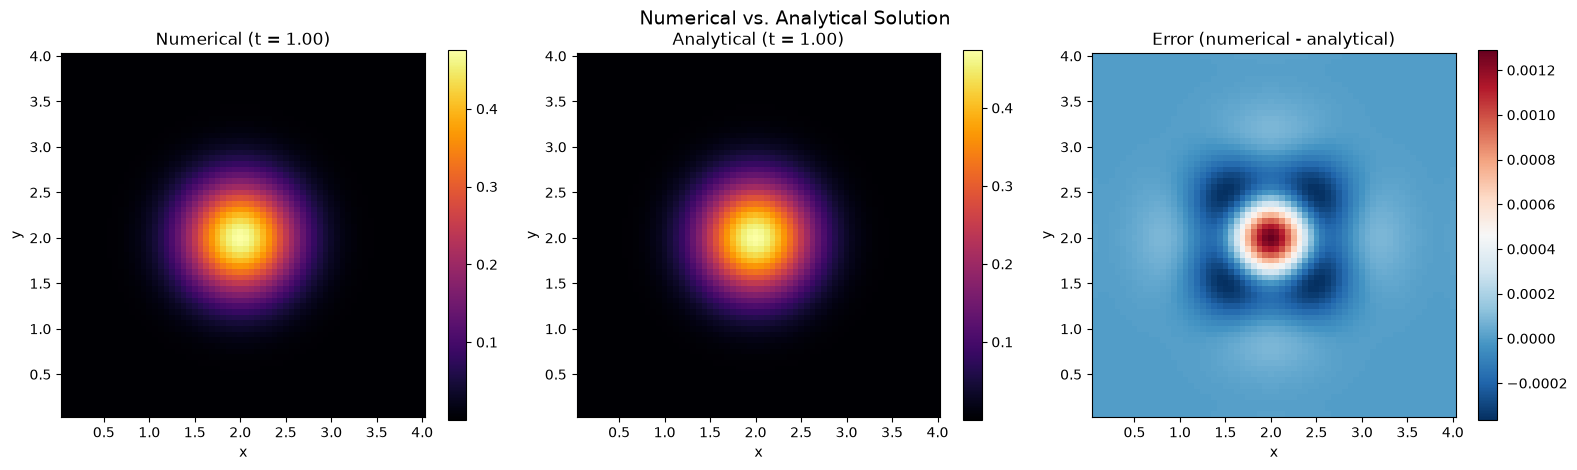

Max absolute error: 0.001290


In [9]:
# Shapes: N_y + 2 = 66 rows and N_x + 2 = 66 columns with the ghosts

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

pcm0 = axes[0].pcolormesh(
    x_grid[interior],
    y_grid[interior],
    numerical_u[interior],
    shading="auto",
    cmap="inferno",
)
plt.colorbar(pcm0, ax=axes[0])
axes[0].set_title(f"Numerical (t = {final_time:.2f})")
axes[0].set_xlabel("x")
axes[0].set_ylabel("y")
axes[0].set_aspect("equal")

pcm1 = axes[1].pcolormesh(
    x_grid[interior],
    y_grid[interior],
    exact_u[interior],
    shading="auto",
    cmap="inferno",
)
plt.colorbar(pcm1, ax=axes[1])
axes[1].set_title(f"Analytical (t = {final_time:.2f})")
axes[1].set_xlabel("x")
axes[1].set_ylabel("y")
axes[1].set_aspect("equal")

# eⱼ,ᵢ = uⱼ,ᵢ − u_exact,ⱼ,ᵢ
error = numerical_u - exact_u  # → (N_y + 2, N_x + 2)
pcm2 = axes[2].pcolormesh(
    x_grid[interior],
    y_grid[interior],
    error[interior],
    shading="auto",
    cmap="RdBu_r",
)
plt.colorbar(pcm2, ax=axes[2])
axes[2].set_title("Error (numerical - analytical)")
axes[2].set_xlabel("x")
axes[2].set_ylabel("y")
axes[2].set_aspect("equal")

plt.suptitle("Numerical vs. Analytical Solution", fontsize=14)
plt.tight_layout()
plt.show()

# ‖e‖_∞ = maxⱼ,ᵢ |eⱼ,ᵢ|
max_error = jnp.max(jnp.abs(error[interior]))  # → ()
print(f"Max absolute error: {float(max_error):.6f}")

## 6. Energy decay

Diffusion dissipates energy. The total energy,

$$
E(t) = \frac{1}{2} \int_0^{L_y} \int_0^{L_x} u(x, y, t)^2 \mathrm{d}x \mathrm{d}y \approx \frac{\Delta x \Delta y}{2} \sum_{j=1}^{N_y} \sum_{i=1}^{N_x} u_{j,i}(t)^2
$$

should decrease monotonically.

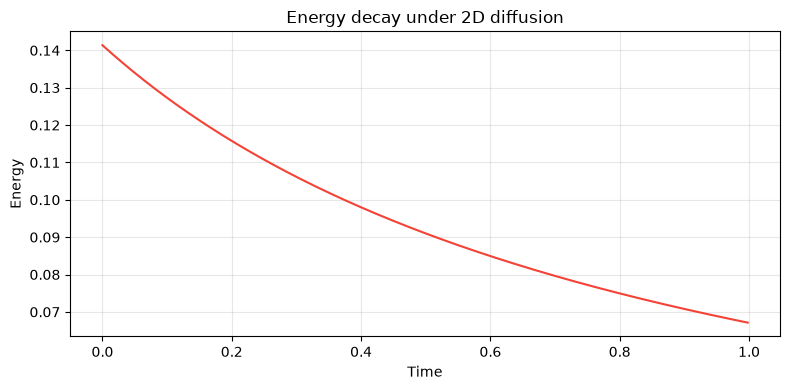

Energy: initial = 0.141372, final = 0.067127
Ratio: 0.4748


In [10]:
# Shapes: N_T = 500 saved snapshots; N_y = 64 rows and N_x = 64 columns interior

x_spacing = float(model.grid.dx)
y_spacing = float(model.grid.dy)

# uⱼ,ᵢ(tₖ) without ghosts
interior_u = solution.ys.u[:, *interior]  # → (N_T, N_y, N_x)
# uⱼ,ᵢ(tₖ)²
u_squared = interior_u**2  # → (N_T, N_y, N_x)
# Σⱼ Σᵢ uⱼ,ᵢ(tₖ)²
total_u_squared = einx.sum("t [y x] -> t", u_squared)  # → (N_T,)
# E(tₖ) = (Δx Δy / 2) Σⱼ Σᵢ uⱼ,ᵢ(tₖ)²
half_sum = 0.5 * total_u_squared  # → (N_T,)
energy = half_sum * x_spacing * y_spacing  # → (N_T,)

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(save_times, energy, lw=1.5, color="#F44336")
ax.set_xlabel("Time")
ax.set_ylabel("Energy")
ax.set_title("Energy decay under 2D diffusion")
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print(f"Energy: initial = {float(energy[0]):.6f}, final = {float(energy[-1]):.6f}")
print(f"Ratio: {float(energy[-1] / energy[0]):.4f}")

## 7. Gradient through the diffusion coefficient

We can compute $\partial \mathcal{L} / \partial \nu$ to answer: "how does the total energy at final time change if we increase the diffusion coefficient?" Here the loss is the sum of squares of the field at $t_1 = 0.5$ over every cell, including the ghosts,

$$
\mathcal{L}(\nu) = \sum_{j=0}^{N_y + 1} \sum_{i=0}^{N_x + 1} u_{j,i}(t_1; \nu)^2
$$

In [11]:
# Shapes: N_y + 2 = 66 rows and N_x + 2 = 66 columns with the ghosts


# today (equinox)
@eqx.filter_grad
def grad_wrt_model(model):
    """Gradient of the loss ℒ(ν) with respect to every float leaf of the model."""
    # today (sesmax_core, diffrax)
    # u(x, y, t₁; ν)
    final_solution = model.integrate(initial_state, t0=0.0, t1=0.5, dt=0.002)
    # ℒ(ν) = Σⱼ Σᵢ uⱼ,ᵢ(t₁)²
    loss = jnp.sum(final_solution.ys.u**2)  # → ()
    return loss


# ∂ℒ/∂ν
model_grads = grad_wrt_model(model)

print("--- Gradient w.r.t. diffusion coefficient ---")
print(f"  dL/d(nu) = {model_grads.params.nu:.6f}")
print("  (negative => increasing nu decreases total energy, as expected)")

--- Gradient w.r.t. diffusion coefficient ---


  dL/d(nu) = -332.448761
  (negative => increasing nu decreases total energy, as expected)


## 8. Peak decay over time

The analytical peak decays as $\sigma_0^2 / (\sigma_0^2 + 2 \nu t)$. We compare this prediction against the numerical peak.

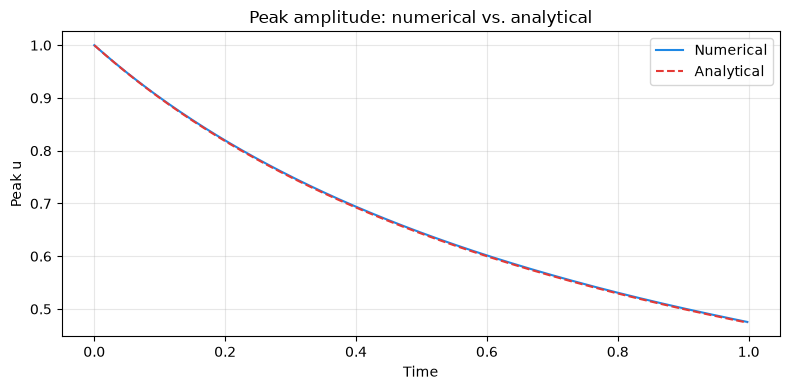

In [12]:
# Shapes: N_T = 500 saved snapshots; N_y = 64 rows and N_x = 64 columns interior

# Uₖ = maxⱼ,ᵢ uⱼ,ᵢ(tₖ)
numerical_peak = einx.max("t [y x] -> t", interior_u)  # → (N_T,)
# U_exact(tₖ) = σ₀² / (σ₀² + 2 ν tₖ)
analytical_peak = bump_width**2 / (bump_width**2 + 2.0 * viscosity * save_times)

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(save_times, numerical_peak, lw=1.5, label="Numerical", color="#1E88E5")
ax.plot(
    save_times, analytical_peak, lw=1.5, ls="--", label="Analytical", color="#E53935"
)
ax.set_xlabel("Time")
ax.set_ylabel("Peak u")
ax.set_title("Peak amplitude: numerical vs. analytical")
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Summary

| Concept | API |
| --- | --- |
| Create model | `Diffusion2D.create(nx=64, ny=64, Lx=4.0, Ly=4.0, nu=0.05)` |
| State | `Diffusion2DState(u=initial_u)` |
| Analytical solution | $\sigma(t) = \sqrt{\sigma_0^2 + 2 \nu t}$ |
| Energy dissipation | monotonic decay of $\sum u^2$ |
| Grad w.r.t. $\nu$ | `eqx.filter_grad(loss)(model)` |

**Next:** Step 8 combines nonlinear convection and diffusion into the 2D Burgers equation.